# NHS Scotland A&E Performance – Data Cleaning

**Goal:** Clean Public Health Scotland open data on A&E waiting times and bed occupancy so it can be analysed and used in a Power BI dashboard.

**Data source:** Scottish Health and Social Care Open Data (opendata.nhs.scot), UK Open Government Licence.

## 1. Setup
Import the libraries we need and define the folder paths and the 95% four-hour target.

Run code in terminal for installing dependencies - py -3.15 -m pip install -r requirements.txt

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")

pd.set_option("display.max_columns", 50)
TARGET_4H = 95  # Scottish Government standard: 95% seen within 4 hours

## 2. Load the raw data
Load the four CSV files downloaded from Public Health Scotland:
- **A&E monthly activity**: attendances and 4-hour performance by hospital and month
- **Beds (quarterly)**: bed occupancy by health board
- **Health boards**: lookup of board codes to names
- **Hospitals**: lookup of hospital codes to names

Then check how many rows and columns each file has.

In [3]:
ae_raw   = pd.read_csv(RAW / "ae_monthly.csv")
beds_raw = pd.read_csv(RAW / "beds_quarterly.csv")
hb_raw   = pd.read_csv(RAW / "health_boards.csv")
hosp_raw = pd.read_csv(RAW / "hospital_codes.csv")

print("A&E:          ", ae_raw.shape)
print("Beds:         ", beds_raw.shape)
print("Health boards:", hb_raw.shape)
print("Hospitals:    ", hosp_raw.shape)

A&E:           (40066, 26)
Beds:          (29930, 20)
Health boards: (18, 5)
Hospitals:     (244, 15)


## 3. Explore the A&E data
Before cleaning, check:
- what the first few rows look like
- which months the data covers
- what the department types and attendance categories are
- which columns have missing values

In [4]:
display(ae_raw.head())

print("First month:", ae_raw["Month"].min())
print("Last month: ", ae_raw["Month"].max())

print("\nDepartment types:", ae_raw["DepartmentType"].unique())
print("Attendance categories:", ae_raw["AttendanceCategory"].unique())

missing = ae_raw.isna().sum()
print("\nMissing values per column:")
print(missing[missing > 0])

,Month,Country,HBT,TreatmentLocation,DepartmentType,AttendanceCategory,NumberOfAttendancesAll,NumberWithin4HoursAll,NumberOver4HoursAll,PercentageWithin4HoursAll,NumberOfAttendancesEpisode,NumberOfAttendancesEpisodeQF,NumberWithin4HoursEpisode,NumberWithin4HoursEpisodeQF,NumberOver4HoursEpisode,NumberOver4HoursEpisodeQF,PercentageWithin4HoursEpisode,PercentageWithin4HoursEpisodeQF,NumberOver8HoursEpisode,NumberOver8HoursEpisodeQF,PercentageOver8HoursEpisode,PercentageOver8HoursEpisodeQF,NumberOver12HoursEpisode,NumberOver12HoursEpisodeQF,PercentageOver12HoursEpisode,PercentageOver12HoursEpisodeQF
0,200707,S92000003,S08000015,A101H,Type 3,Unplanned,252,252,0,100.0,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z
1,200707,S92000003,S08000015,A101H,Type 3,All,252,252,0,100.0,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z
2,200707,S92000003,S08000015,A111H,Type 1,Unplanned,5414,5290,124,97.7,5414.0,NaN,5290.0,NaN,124.0,NaN,97.7,NaN,26.0,NaN,0.5,NaN,24.0,NaN,0.4,NaN
3,200707,S92000003,S08000015,A111H,Type 1,All,5414,5290,124,97.7,5414.0,NaN,5290.0,NaN,124.0,NaN,97.7,NaN,26.0,NaN,0.5,NaN,24.0,NaN,0.4,NaN
4,200707,S92000003,S08000015,A207H,Type 3,Unplanned,92,92,0,100.0,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z,NaN,z


First month: 200707
Last month:  202608

Department types: <StringArray>
['Type 3', 'Type 1']
Length: 2, dtype: str
Attendance categories: <StringArray>
['Unplanned', 'All', 'New planned']
Length: 3, dtype: str

Missing values per column:
NumberOfAttendancesEpisode         16990
NumberOfAttendancesEpisodeQF       23076
NumberWithin4HoursEpisode          16990
NumberWithin4HoursEpisodeQF        23076
NumberOver4HoursEpisode            16990
NumberOver4HoursEpisodeQF          23076
PercentageWithin4HoursEpisode      16990
PercentageWithin4HoursEpisodeQF    23076
NumberOver8HoursEpisode            16990
NumberOver8HoursEpisodeQF          23076
PercentageOver8HoursEpisode        16990
PercentageOver8HoursEpisodeQF      23076
NumberOver12HoursEpisode           16990
NumberOver12HoursEpisodeQF         23076
PercentageOver12HoursEpisode       16990
PercentageOver12HoursEpisodeQF     23076
dtype: int64


## 4. Clean the A&E data

**Findings from exploration:**
- Data covers July 2007 to August 2026.
- `AttendanceCategory` has three values: *Unplanned*, *New planned* and *All*. *All* is the total of the other two, so keeping every row would count patients twice. **Keep only *All*.**
- The `QF` (qualifier flag) columns are mostly empty and not needed for analysis. **Drop them.**
- The "Episode" columns (including 8-hour and 12-hour waits) are mainly populated for Type 1 Emergency Departments, not Type 3 minor injury units.

In [5]:
ae = ae_raw[ae_raw["AttendanceCategory"] == "All"].copy()

qf_columns = [col for col in ae.columns if col.endswith("QF")]
ae = ae.drop(columns=qf_columns)

print("Rows before:", len(ae_raw))
print("Rows after: ", len(ae))
print("Columns now:", ae.shape[1])

duplicates = ae.duplicated(subset=["Month", "TreatmentLocation", "DepartmentType"]).sum()
print("Duplicate hospital-month rows:", duplicates)

Rows before: 40066
Rows after:  18961
Columns now: 18
Duplicate hospital-month rows: 1


### 4.1 Investigate the duplicate
The duplicate check found 1 hospital-month appearing twice. Before removing anything, look at both rows to understand why.

In [6]:
dup_rows = ae[ae.duplicated(subset=["Month", "TreatmentLocation", "DepartmentType"], keep=False)]
display(dup_rows)

,Month,Country,HBT,TreatmentLocation,DepartmentType,AttendanceCategory,NumberOfAttendancesAll,NumberWithin4HoursAll,NumberOver4HoursAll,PercentageWithin4HoursAll,NumberOfAttendancesEpisode,NumberWithin4HoursEpisode,NumberOver4HoursEpisode,PercentageWithin4HoursEpisode,NumberOver8HoursEpisode,PercentageOver8HoursEpisode,NumberOver12HoursEpisode,PercentageOver12HoursEpisode
17712,201505,S92000003,S08000031,G405H,Type 1,All,4990,4267,723,85.5,4990.0,4267.0,723.0,85.5,54.0,1.1,2.0,0.0
17713,201505,S92000003,S08000031,G405H,Type 1,All,137,127,10,92.7,137.0,127.0,10.0,92.7,0.0,0.0,0.0,0.0


### 4.2 Decision: combine the split record
Hospital G405H (NHS Greater Glasgow & Clyde) has two rows for May 2015, with 4,990 and 137 attendances. These are not identical copies but two parts of the same month's activity (the Queen Elizabeth University Hospital, which opened in 2015). **Both rows are real activity, so they are summed rather than deleted.**

Percentage columns are dropped here because percentages cannot be added together. They will be recalculated from the counts later.

In [7]:
pct_columns = [col for col in ae.columns if col.startswith("Percentage")]
ae = ae.drop(columns=pct_columns)

group_cols = ["Month", "Country", "HBT", "TreatmentLocation", "DepartmentType", "AttendanceCategory"]
ae = ae.groupby(group_cols, as_index=False, dropna=False).sum(min_count=1)

print("Rows now:", len(ae))
print("Duplicates:", ae.duplicated(subset=["Month", "TreatmentLocation", "DepartmentType"]).sum())

display(ae[(ae["Month"] == 201505) & (ae["TreatmentLocation"] == "G405H")])

Rows now: 18960
Duplicates: 0


,Month,Country,HBT,TreatmentLocation,DepartmentType,AttendanceCategory,NumberOfAttendancesAll,NumberWithin4HoursAll,NumberOver4HoursAll,NumberOfAttendancesEpisode,NumberWithin4HoursEpisode,NumberOver4HoursEpisode,NumberOver8HoursEpisode,NumberOver12HoursEpisode
8895,201505,S92000003,S08000031,G405H,Type 1,All,5127,4394,733,5127.0,4394.0,733.0,54.0,2.0


### 4.3 Create a proper date and tidy column names
- `Month` is stored as a number (e.g. 201505), so convert it into a real date (1 May 2015). This lets us sort, filter and plot by time correctly.
- Rename columns to short, consistent snake_case names.
- Drop `Country` and `AttendanceCategory`, which now have only one value each (Scotland / All).

In [8]:
ae["date"] = pd.to_datetime(ae["Month"].astype(str), format="%Y%m")

ae = ae.rename(columns={
    "HBT": "hb_code",
    "TreatmentLocation": "location_code",
    "DepartmentType": "department_type",
    "NumberOfAttendancesAll": "attendances",
    "NumberWithin4HoursAll": "within_4h",
    "NumberOver4HoursAll": "over_4h",
    "NumberOfAttendancesEpisode": "attendances_episode",
    "NumberWithin4HoursEpisode": "within_4h_episode",
    "NumberOver4HoursEpisode": "over_4h_episode",
    "NumberOver8HoursEpisode": "over_8h",
    "NumberOver12HoursEpisode": "over_12h",
})

ae = ae.drop(columns=["Month", "Country", "AttendanceCategory"])

print(ae.dtypes)
display(ae.head())

hb_code                           str
location_code                     str
department_type                   str
attendances                     int64
within_4h                       int64
over_4h                         int64
attendances_episode           float64
within_4h_episode             float64
over_4h_episode               float64
over_8h                       float64
over_12h                      float64
date                   datetime64[us]
dtype: object


,hb_code,location_code,department_type,attendances,within_4h,over_4h,attendances_episode,within_4h_episode,over_4h_episode,over_8h,over_12h,date
0,S08000015,A101H,Type 3,252,252,0,NaN,NaN,NaN,NaN,NaN,2007-07-01
1,S08000015,A111H,Type 1,5414,5290,124,5414.0,5290.0,124.0,26.0,24.0,2007-07-01
2,S08000015,A207H,Type 3,92,92,0,NaN,NaN,NaN,NaN,NaN,2007-07-01
3,S08000015,A210H,Type 1,3530,3355,175,3530.0,3355.0,175.0,3.0,1.0,2007-07-01
4,S08000016,B103H,Type 3,20,20,0,NaN,NaN,NaN,NaN,NaN,2007-07-01


### 4.4 Add health board names
Health boards are stored as 9-digit codes (e.g. S08000015). Join the health board lookup table to add readable names such as "Ayrshire and Arran".

All 18 lookup rows are kept (including archived codes), so that any older codes used in the A&E data still get a name.

In [9]:
hb_lookup = hb_raw[["HB", "HBName"]].copy()
hb_lookup.columns = ["hb_code", "hb_name"]
hb_lookup["hb_name"] = hb_lookup["hb_name"].str.replace("NHS ", "", regex=False)

ae = ae.merge(hb_lookup, on="hb_code", how="left", validate="many_to_one")

print("Rows still:", len(ae))
print("Rows without a board name:", ae["hb_name"].isna().sum())
print()
print(ae["hb_name"].value_counts())

Rows still: 18960
Rows without a board name: 0

hb_name
Highland                     4182
Grampian                     3149
Greater Glasgow and Clyde    2037
Tayside                      1865
Ayrshire and Arran           1147
Lothian                      1141
Dumfries and Galloway        1063
Lanarkshire                   997
Fife                          908
Borders                       859
Western Isles                 690
Forth Valley                  462
Orkney                        230
Shetland                      230
Name: count, dtype: int64


### 4.5 Add hospital names
Hospitals are stored as 5-character codes (e.g. G405H). Join the hospital lookup table to add readable names. Any A&E site not found in the lookup is labelled "Unknown (code)" rather than dropped, so no activity is lost.

In [10]:
print(hosp_raw.columns.tolist())

hosp_lookup = hosp_raw[["HospitalCode", "HospitalName"]].copy()
hosp_lookup.columns = ["location_code", "hospital_name"]

ae = ae.merge(hosp_lookup, on="location_code", how="left", validate="many_to_one")

missing_names = ae["hospital_name"].isna()
print("\nRows still:", len(ae))
print("Rows without a hospital name:", missing_names.sum())
print("Codes without a name:", ae.loc[missing_names, "location_code"].unique())

ae["hospital_name"] = ae["hospital_name"].fillna("Unknown (" + ae["location_code"] + ")")

print("\nG405H is:", ae.loc[ae["location_code"] == "G405H", "hospital_name"].iloc[0])

['HospitalCode', 'HospitalName', 'AddressLine1', 'AddressLine2', 'AddressLine2QF', 'AddressLine3', 'AddressLine3QF', 'AddressLine4', 'AddressLine4QF', 'Postcode', 'HealthBoard', 'HSCP', 'CouncilArea', 'IntermediateZone', 'DataZone']

Rows still: 18960
Rows without a hospital name: 1475
Codes without a name: <StringArray>
['A207H', 'N332H', 'N451H', 'C103B', 'C110H', 'C117J', 'H210H', 'H214H',
 'H227B', 'T208H', 'T305H', 'T357C', 'T207H', 'N683C', 'H221B']
Length: 15, dtype: str

G405H is: Queen Elizabeth University Hospital


### 4.6 Check the impact of unnamed sites
15 site codes (1,475 rows) are not in the current hospital lookup, possibly community clinics or sites that have since closed. Before deciding what to do, measure what share of total attendances they represent, and when they were active.

In [11]:
unknown = ae[ae["hospital_name"].str.startswith("Unknown")]

share = unknown["attendances"].sum() / ae["attendances"].sum() * 100
print(f"Share of all attendances at unnamed sites: {share:.2f}%")

summary = (
    unknown.groupby(["location_code", "hb_name", "department_type"])
    .agg(first_month=("date", "min"),
         last_month=("date", "max"),
         attendances=("attendances", "sum"))
    .sort_values("attendances", ascending=False)
)
display(summary)

Share of all attendances at unnamed sites: 0.84%


,,,first_month,last_month,attendances
location_code,hb_name,department_type,,,
T357C,Tayside,Type 3,2007-07-01,2020-03-01,70388
H214H,Highland,Type 3,2007-07-01,2022-03-01,63062
H227B,Highland,Type 3,2007-07-01,2026-08-01,34078
T305H,Tayside,Type 3,2007-07-01,2019-06-01,31365
C103B,Highland,Type 3,2007-07-01,2009-12-01,14953
H210H,Highland,Type 3,2007-07-01,2019-08-01,12813
C110H,Highland,Type 3,2007-07-01,2009-12-01,9377
N332H,Grampian,Type 3,2007-07-01,2020-03-01,6916
N451H,Grampian,Type 3,2007-07-01,2019-11-01,3865


**Decision:** The 15 unnamed sites account for only **0.84% of attendances**. All are Type 3 minor injury units, and 14 of 15 stopped reporting before 2023 (likely closed or recoded). They are **kept** and labelled "Unknown (code)", so their activity still counts towards health board and Scotland totals. Only hospital-level views are affected.

### 4.7 Calculate KPI columns
For each hospital and month:
- **pct_within_4h**: % of patients seen within 4 hours
- **target_4h**: the 95% standard
- **met_target**: True if the hospital met the standard that month
- **gap_to_target**: percentage points above or below 95%

Note: these row-level percentages are only correct for a single hospital-month. For board or Scotland totals, the percentage must be recalculated from summed counts, not averaged.

In [12]:
ae["pct_within_4h"] = (ae["within_4h"] / ae["attendances"] * 100).round(1)
ae["target_4h"] = TARGET_4H
ae["met_target"] = ae["pct_within_4h"] >= TARGET_4H
ae["gap_to_target"] = (ae["pct_within_4h"] - TARGET_4H).round(1)

check = (ae["within_4h"] + ae["over_4h"] == ae["attendances"]).mean() * 100
print(f"Rows where within + over = total: {check:.1f}%")
print("Rows with zero attendances:", (ae["attendances"] == 0).sum())

display(ae[["date", "hospital_name", "hb_name", "attendances",
            "within_4h", "pct_within_4h", "met_target", "gap_to_target"]].head())

Rows where within + over = total: 100.0%
Rows with zero attendances: 0


,date,hospital_name,hb_name,attendances,within_4h,pct_within_4h,met_target,gap_to_target
0,2007-07-01,Arran War Memorial Hospital,Ayrshire and Arran,252,252,100.0,True,5.0
1,2007-07-01,University Hospital Crosshouse,Ayrshire and Arran,5414,5290,97.7,True,2.7
2,2007-07-01,Unknown (A207H),Ayrshire and Arran,92,92,100.0,True,5.0
3,2007-07-01,University Hospital Ayr,Ayrshire and Arran,3530,3355,95.0,True,0.0
4,2007-07-01,The Knoll Hospital,Borders,20,20,100.0,True,5.0


## 5. First look: Scotland-wide trend
Sum attendances and patients seen within 4 hours across all sites for each month, then **recalculate** the percentage from those totals. Plot it against the 95% target.

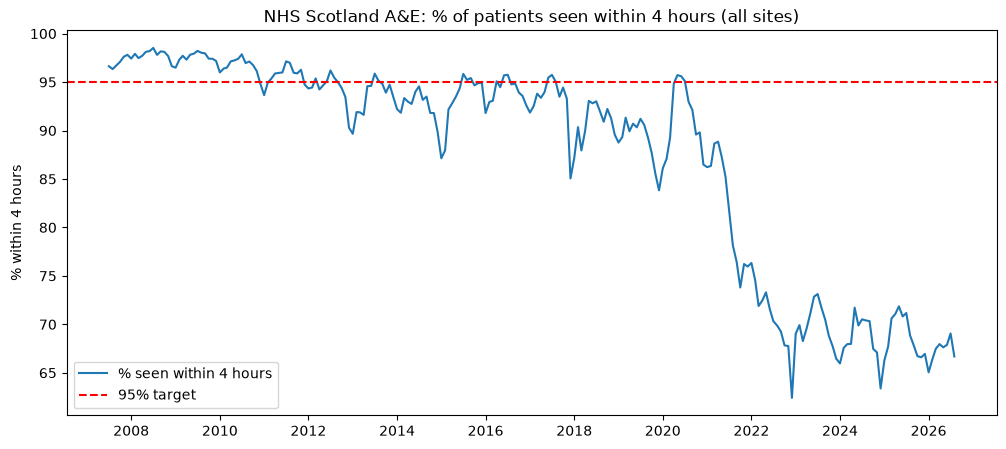

Last month Scotland met the 95% target: July 2020
Latest month (August 2026): 66.7%


In [13]:
scotland = ae.groupby("date", as_index=False)[["attendances", "within_4h"]].sum()
scotland["pct_within_4h"] = scotland["within_4h"] / scotland["attendances"] * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(scotland["date"], scotland["pct_within_4h"], label="% seen within 4 hours")
ax.axhline(TARGET_4H, color="red", linestyle="--", label="95% target")
ax.set_title("NHS Scotland A&E: % of patients seen within 4 hours (all sites)")
ax.set_ylabel("% within 4 hours")
ax.legend()
plt.show()

met = scotland[scotland["pct_within_4h"] >= TARGET_4H]
if len(met) > 0:
    print("Last month Scotland met the 95% target:", met["date"].max().strftime("%B %Y"))
else:
    print("Scotland did not meet the 95% target in any month.")

latest = scotland.iloc[-1]
print(f"Latest month ({latest['date']:%B %Y}): {latest['pct_within_4h']:.1f}%")

The last month Scotland met the target was **July 2020** (during the COVID lockdown, when attendances fell). The latest month (**August 2026**) was **66.7%**, which is 28.3 percentage points below the standard.

### 5.1 Major Emergency Departments vs Minor Injury Units
Split the trend by department type:
- **Type 1**: major Emergency Departments (consultant-led, 24/7)
- **Type 3**: Minor Injury Units and smaller sites

This shows where the pressure on the 4-hour standard really sits.

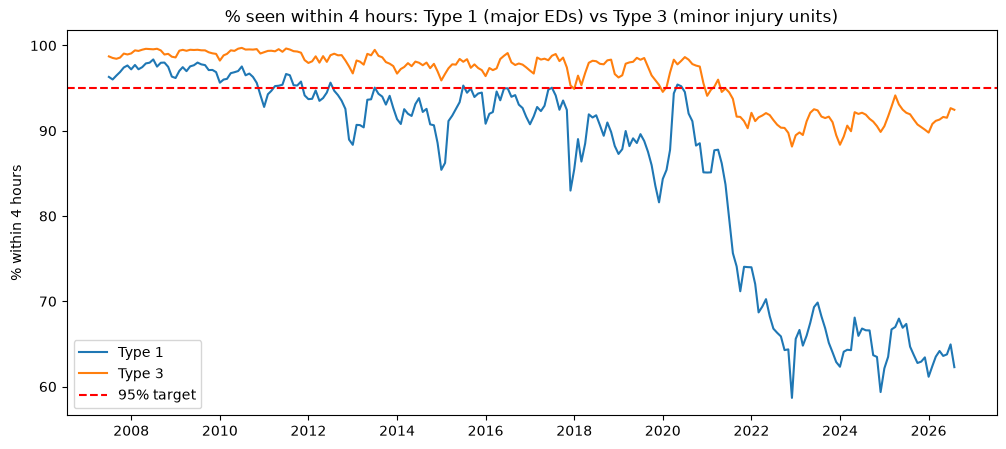

,department_type,attendances,share_of_attendances,pct_within_4h
458,Type 1,130081,85.4,62.3
459,Type 3,22250,14.6,92.5


In [14]:
by_type = ae.groupby(["date", "department_type"], as_index=False)[["attendances", "within_4h"]].sum()
by_type["pct_within_4h"] = by_type["within_4h"] / by_type["attendances"] * 100

fig, ax = plt.subplots(figsize=(12, 5))
for dept, group in by_type.groupby("department_type"):
    ax.plot(group["date"], group["pct_within_4h"], label=dept)
ax.axhline(TARGET_4H, color="red", linestyle="--", label="95% target")
ax.set_title("% seen within 4 hours: Type 1 (major EDs) vs Type 3 (minor injury units)")
ax.set_ylabel("% within 4 hours")
ax.legend()
plt.show()

latest_month = by_type["date"].max()
latest = by_type[by_type["date"] == latest_month].copy()
latest["share_of_attendances"] = latest["attendances"] / latest["attendances"].sum() * 100
display(latest[["department_type", "attendances", "share_of_attendances", "pct_within_4h"]].round(1))

**Key observations (by department type):**
- **Type 1 major Emergency Departments** handle **85.4% of attendances** (August 2026) and saw only **62.3%** of patients within 4 hours, lower than the all-sites figure of 66.7%.
- **Type 3 minor injury units** perform much better (**92.5%**) but handle only 14.6% of patients. Including them **makes the headline figure look better than major ED performance really is**.
- Both types met the standard before 2011. The post-2021 collapse is driven by Type 1 departments, which have fallen to around 60–68%.

*Implication for the dashboard: include a department type filter, and report Type 1 performance alongside the overall figure.*

## 6. Explore and clean the bed occupancy data
The beds file is quarterly and contains rows at several levels (Scotland, health board, hospital) and for many specialties. Explore it first to work out which rows we need.

In [16]:
print(beds_raw.columns.tolist())
display(beds_raw.head())

print("Quarters:", beds_raw["Quarter"].min(), "to", beds_raw["Quarter"].max())
print("Number of specialties:", beds_raw["SpecialtyName"].nunique())
print("First 20 specialties:", beds_raw["SpecialtyName"].unique()[:20])

print("\nHBQF values:", beds_raw["HBQF"].unique())
print("LocationQF values:", beds_raw["LocationQF"].unique())
print("SpecialtyQF values:", beds_raw["SpecialtyQF"].unique())

['Quarter', 'QuarterQF', 'HB', 'HBQF', 'Location', 'LocationQF', 'Specialty', 'SpecialtyQF', 'SpecialtyName', 'SpecialtyNameQF', 'AllStaffedBeddays', 'AllStaffedBeddaysQF', 'TotalOccupiedBeddays', 'TotalOccupiedBeddaysQF', 'AverageAvailableStaffedBeds', 'AverageAvailableStaffedBedsQF', 'AverageOccupiedBeds', 'AverageOccupiedBedsQF', 'PercentageOccupancy', 'PercentageOccupancyQF']


,Quarter,QuarterQF,HB,HBQF,Location,LocationQF,Specialty,SpecialtyQF,SpecialtyName,SpecialtyNameQF,AllStaffedBeddays,AllStaffedBeddaysQF,TotalOccupiedBeddays,TotalOccupiedBeddaysQF,AverageAvailableStaffedBeds,AverageAvailableStaffedBedsQF,AverageOccupiedBeds,AverageOccupiedBedsQF,PercentageOccupancy,PercentageOccupancyQF
0,2020Q4,NaN,S08000015,NaN,A111H,NaN,C2,NaN,Accident & Emergency,NaN,6,NaN,6,NaN,0.065217,NaN,0.065217,NaN,100.0,NaN
1,2020Q4,NaN,S08000015,NaN,A210H,NaN,C2,NaN,Accident & Emergency,NaN,36,NaN,36,NaN,0.391304,NaN,0.391304,NaN,100.0,NaN
2,2020Q4,NaN,S08000015,NaN,S08000015,d,C2,NaN,Accident & Emergency,NaN,42,NaN,42,NaN,0.456522,NaN,0.456522,NaN,100.0,NaN
3,2021Q1,NaN,S08000015,NaN,A111H,NaN,C2,NaN,Accident & Emergency,NaN,6,NaN,6,NaN,0.066667,NaN,0.066667,NaN,100.0,NaN
4,2021Q1,NaN,S08000015,NaN,A210H,NaN,C2,NaN,Accident & Emergency,NaN,34,NaN,34,NaN,0.377778,NaN,0.377778,NaN,100.0,NaN


Quarters: 2020Q4 to 2025Q4
Number of specialties: 76
First 20 specialties: <StringArray>
[               'Accident & Emergency',                           'All Acute',
                     'All Specialties',                        'Anaesthetics',
                          'Cardiology',                   'Clinical Oncology',
                  'Clinical Radiology',           'Community Dental Practice',
                  'Community Grouping',                     'Dental Grouping',
                         'Dermatology',            'Ear, Nose & Throat (ENT)',
                  'Emergency Grouping',            'Endocrinology & Diabetes',
                 'Forensic Psychiatry',            'GP Other than Obstetrics',
                    'Gastroenterology',                    'General Medicine',
 'General Psychiatry (Mental Illness)',                     'General Surgery']
Length: 20, dtype: str

HBQF values: <StringArray>
[nan, 'd']
Length: 2, dtype: str
LocationQF values: <StringArray>
[nan

### 6.1 Keep board-level totals only
**Findings:**
- Data covers **2020 Q4 to 2025 Q4** only (shorter than the A&E data).
- The file contains both hospital rows and summary rows. Summary rows are flagged with `LocationQF = "d"`.
- `SpecialtyName` includes totals: **All Specialties** and **All Acute**. *All Acute* (medical and surgical beds) is most relevant to A&E, because it is where emergency patients are admitted.
- `SpecialtyQF` is always empty, so specialty totals are identified by name rather than by flag.

**Decision:** keep only summary rows (`LocationQF = "d"`) for *All Acute* and *All Specialties*, to avoid double counting.

In [17]:
beds = beds_raw[
    (beds_raw["LocationQF"] == "d") &
    (beds_raw["SpecialtyName"].isin(["All Acute", "All Specialties"]))
].copy()

print("Rows kept:", len(beds))
print("\nBoard / area codes found:", beds["HB"].unique())

dupes = beds.duplicated(subset=["Quarter", "HB", "SpecialtyName"]).sum()
print("\nDuplicate board-quarter-specialty rows:", dupes)

print("\nAll column names:")
for col in beds.columns:
    print("  ", col)

Rows kept: 672

Board / area codes found: <StringArray>
['S08000015', 'S08000016', 'S08000017', 'S08000029', 'S08000019', 'S08000020',
 'S08000031', 'S08000022', 'S08000032', 'S08000024', 'S08000025', 'S08000026',
 'S08000030', 'S08000028',    'SB0801', 'S92000003']
Length: 16, dtype: str

Duplicate board-quarter-specialty rows: 0

All column names:
   Quarter
   QuarterQF
   HB
   HBQF
   Location
   LocationQF
   Specialty
   SpecialtyQF
   SpecialtyName
   SpecialtyNameQF
   AllStaffedBeddays
   AllStaffedBeddaysQF
   TotalOccupiedBeddays
   TotalOccupiedBeddaysQF
   AverageAvailableStaffedBeds
   AverageAvailableStaffedBedsQF
   AverageOccupiedBeds
   AverageOccupiedBedsQF
   PercentageOccupancy
   PercentageOccupancyQF


### 6.2 Tidy the beds data
- Convert `Quarter` (e.g. 2024Q3) into a real date (first day of the quarter).
- Rename columns to snake_case and drop the QF columns.
- Add area names. The lookup covers the 14 health boards; **Scotland** (S92000003) and **Golden Jubilee** (SB0801, a national special board) are added manually.
- Add an `area_type` column (Health board / National board / Scotland), so the dashboard map can show health boards only.
- Check that occupancy % = occupied bed days ÷ staffed bed days.

In [18]:
beds = beds.drop(columns=[c for c in beds.columns if c.endswith("QF")])

beds["date"] = pd.PeriodIndex(beds["Quarter"], freq="Q").to_timestamp()

beds = beds.rename(columns={
    "Quarter": "quarter",
    "HB": "hb_code",
    "SpecialtyName": "specialty",
    "AllStaffedBeddays": "staffed_beddays",
    "TotalOccupiedBeddays": "occupied_beddays",
    "AverageAvailableStaffedBeds": "avg_available_beds",
    "AverageOccupiedBeds": "avg_occupied_beds",
    "PercentageOccupancy": "pct_occupancy",
})

extra = pd.DataFrame({"hb_code": ["S92000003", "SB0801"],
                      "hb_name": ["Scotland", "Golden Jubilee"]})
area_lookup = pd.concat([hb_lookup, extra], ignore_index=True)
beds = beds.merge(area_lookup, on="hb_code", how="left", validate="many_to_one")

beds["area_type"] = "Health board"
beds.loc[beds["hb_code"] == "S92000003", "area_type"] = "Scotland"
beds.loc[beds["hb_code"] == "SB0801", "area_type"] = "National board"

recalc = beds["occupied_beddays"] / beds["staffed_beddays"] * 100
print("Biggest difference vs published occupancy %:", round((recalc - beds["pct_occupancy"]).abs().max(), 2))
print("Rows without an area name:", beds["hb_name"].isna().sum())

keep = ["date", "quarter", "hb_code", "hb_name", "area_type", "specialty",
        "staffed_beddays", "occupied_beddays", "avg_available_beds", "avg_occupied_beds", "pct_occupancy"]
beds = beds[[c for c in keep if c in beds.columns]]

print(beds.shape)
display(beds.head())

Biggest difference vs published occupancy %: 0.0
Rows without an area name: 0
(672, 11)


,date,quarter,hb_code,hb_name,area_type,specialty,staffed_beddays,occupied_beddays,avg_available_beds,avg_occupied_beds,pct_occupancy
0,2020-10-01,2020Q4,S08000015,Ayrshire and Arran,Health board,All Acute,88117,77380,957.793478,841.086957,87.815064
1,2021-01-01,2021Q1,S08000015,Ayrshire and Arran,Health board,All Acute,86788,76215,964.311111,846.833333,87.817440
2,2021-04-01,2021Q2,S08000015,Ayrshire and Arran,Health board,All Acute,86764,77846,953.450549,855.450549,89.721543
3,2021-07-01,2021Q3,S08000015,Ayrshire and Arran,Health board,All Acute,90100,82594,979.347826,897.760870,91.669256
4,2021-10-01,2021Q4,S08000015,Ayrshire and Arran,Health board,All Acute,93750,85593,1019.021739,930.358696,91.299200


## 7. Save clean tables
Save analysis-ready tables to `data/processed/` for use in Power BI, following a **star schema**:
- **Fact tables:** `ae_monthly_clean.csv` (hospital × month), `beds_quarterly_clean.csv` (area × quarter × specialty)
- **Dimension tables:** `dim_health_board.csv`, `dim_hospital.csv`

Final checks confirm that every code in the fact tables exists in the dimension tables.

In [19]:
ae = ae[["date", "hb_code", "hb_name", "location_code", "hospital_name", "department_type",
         "attendances", "within_4h", "over_4h", "pct_within_4h", "target_4h", "met_target", "gap_to_target",
         "attendances_episode", "within_4h_episode", "over_4h_episode", "over_8h", "over_12h"]]
ae = ae.sort_values(["date", "hb_name", "hospital_name"]).reset_index(drop=True)

dim_health_board = beds[["hb_code", "hb_name", "area_type"]].drop_duplicates().reset_index(drop=True)

dim_hospital = (ae[["location_code", "hospital_name", "hb_code", "hb_name"]]
                .drop_duplicates()
                .reset_index(drop=True))

assert dim_hospital["location_code"].is_unique, "A hospital appears with two boards"
assert set(ae["hb_code"]).issubset(dim_health_board["hb_code"]), "A&E board code missing from dimension"

PROCESSED.mkdir(parents=True, exist_ok=True)
ae.to_csv(PROCESSED / "ae_monthly_clean.csv", index=False)
beds.to_csv(PROCESSED / "beds_quarterly_clean.csv", index=False)
dim_health_board.to_csv(PROCESSED / "dim_health_board.csv", index=False)
dim_hospital.to_csv(PROCESSED / "dim_hospital.csv", index=False)

for f in sorted(PROCESSED.glob("*.csv")):
    df = pd.read_csv(f)
    print(f"{f.name:30} {df.shape[0]:>6,} rows  {df.shape[1]:>3} cols")

ae_monthly_clean.csv           18,960 rows   18 cols
beds_quarterly_clean.csv          672 rows   11 cols
dim_health_board.csv               16 rows    3 cols
dim_hospital.csv                  103 rows    4 cols


## 8. Summary of cleaning
| Step | Result |
|---|---|
| Kept only `AttendanceCategory = All` | Avoided double counting (40,066 → 18,961 rows) |
| Merged split record (QEUH, May 2015) | 4,990 + 137 = 5,127 attendances; 0 duplicates |
| Recalculated % from counts | Percentages never averaged |
| Integrity check | within + over = total on 100% of rows |
| Unnamed sites | 15 Type 3 sites, 0.84% of attendances, kept as "Unknown (code)" |
| Beds | Board totals only; occupancy recalculation matches published figures exactly |

**Outputs:** 2 fact tables and 2 dimension tables in `data/processed/`, ready for Power BI.